In [2]:
'''
| 필드          | 의미          | 설명                        |
| ----------- | ----------- | ------------------------- |
| **CRIM**    | 범죄율         | 지역별 1인당 범죄 발생률            |
| **ZN**      | 주거지역 비율     | 25,000제곱피트 초과 주거용 토지 비율   |
| **INDUS**    비소매상업지역 비율  || 비소매 상업지역이 차지하는 비율         |
| **CHAS**    | 찰스강 인접 여부   | 찰스강 경계에 위치하면 `1`, 아니면 `0` |
| **NOX**     | 질소산화물 농도    | 대기오염 정도                   |
| **RM**      | 평균 방 개수     | 주택당 평균 방 개수               |
| **AGE**     | 노후 주택 비율    | 1940년 이전에 건축된 주택의 비율      |
| **DIS**     | 고용센터까지 거리   | 주요 고용센터까지의 가중 거리          |
| **RAD**     | 고속도로 접근성    | 방사형 고속도로 접근성 지수           |
| **TAX**     | 재산세율        | 10,000달러당 재산세율            |
| **PTRATIO** | 학생/교사 비율    | 지역별 학생 수 대비 교사 수          |
| **B**       | 흑인 인구 관련 지표 | 데이터셋의 원래 정의에 따른 인구 지표     |
| **LSTAT**   | 저소득층 비율     | 해당 지역의 저소득층 인구 비율         |
| **Target**  | 주택가격        | 주택 가격의 중앙값 (`$1,000 단위`)  |
'''

'\n| 필드          | 의미          | 설명                        |\n| ----------- | ----------- | ------------------------- |\n| **CRIM**    | 범죄율         | 지역별 1인당 범죄 발생률            |\n| **ZN**      | 주거지역 비율     | 25,000제곱피트 초과 주거용 토지 비율   |\n| **INDUS**   | 비소매상업지역 비율  | 비소매 상업지역이 차지하는 비율         |\n| **CHAS**    | 찰스강 인접 여부   | 찰스강 경계에 위치하면 `1`, 아니면 `0` |\n| **NOX**     | 질소산화물 농도    | 대기오염 정도                   |\n| **RM**      | 평균 방 개수     | 주택당 평균 방 개수               |\n| **AGE**     | 노후 주택 비율    | 1940년 이전에 건축된 주택의 비율      |\n| **DIS**     | 고용센터까지 거리   | 주요 고용센터까지의 가중 거리          |\n| **RAD**     | 고속도로 접근성    | 방사형 고속도로 접근성 지수           |\n| **TAX**     | 재산세율        | 10,000달러당 재산세율            |\n| **PTRATIO** | 학생/교사 비율    | 지역별 학생 수 대비 교사 수          |\n| **B**       | 흑인 인구 관련 지표 | 데이터셋의 원래 정의에 따른 인구 지표     |\n| **LSTAT**   | 저소득층 비율     | 해당 지역의 저소득층 인구 비율         |\n| **Target**  | 주택가격        | 주택 가격의 중앙값 (`$1,000 단위`)  |\n'

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

bostonDF = pd.read_csv(r"./data/Boston_house.csv")
bostonDF.head()

# target : 1,000달러, 50:50,000달러

,AGE,B,RM,CRIM,DIS,INDUS,LSTAT,NOX,PTRATIO,RAD,ZN,TAX,CHAS,Target
0,65.2,396.90,6.575,0.00632,4.0900,2.31,4.98,0.538,15.3,1,18.0,296,0,24.0
1,78.9,396.90,6.421,0.02731,4.9671,7.07,9.14,0.469,17.8,2,0.0,242,0,21.6
2,61.1,392.83,7.185,0.02729,4.9671,7.07,4.03,0.469,17.8,2,0.0,242,0,34.7
3,45.8,394.63,6.998,0.03237,6.0622,2.18,2.94,0.458,18.7,3,0.0,222,0,33.4
4,54.2,396.90,7.147,0.06905,6.0622,2.18,5.33,0.458,18.7,3,0.0,222,0,36.2


In [5]:
bostonDF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   AGE      506 non-null    float64
 1   B        506 non-null    float64
 2   RM       506 non-null    float64
 3   CRIM     506 non-null    float64
 4   DIS      506 non-null    float64
 5   INDUS    506 non-null    float64
 6   LSTAT    506 non-null    float64
 7   NOX      506 non-null    float64
 8   PTRATIO  506 non-null    float64
 9   RAD      506 non-null    int64  
 10  ZN       506 non-null    float64
 11  TAX      506 non-null    int64  
 12  CHAS     506 non-null    int64  
 13  Target   506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [6]:
bostonDF.describe()
# CRIM(범죄율) : 평균값이 최댓값과 유사하므로 전체적인 범죄율이 높음을 확인
# ZN(주거지역 비율) : 대부분의 관측값이 0임, 일부지역에 치우쳐저 있음
# AGE(노주 주택) : 오른쪽으로 데이터가 많이 치우쳐져 있음. 즉 노후 주택이 많음
# PTRATIO(학생/교사 비율) : 학생 18.4명당 교사 1명 수준의 비율
# LSTAT(저소득층 비율) : 평균이 약 12.6% 

,AGE,B,RM,CRIM,DIS,INDUS,LSTAT,NOX,PTRATIO,RAD,ZN,TAX,CHAS,Target
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,68.574901,356.674032,6.284634,3.613524,3.795043,11.136779,12.653063,0.554695,18.455534,9.549407,11.363636,408.237154,0.069170,22.532806
std,28.148861,91.294864,0.702617,8.601545,2.105710,6.860353,7.141062,0.115878,2.164946,8.707259,23.322453,168.537116,0.253994,9.197104
min,2.900000,0.320000,3.561000,0.006320,1.129600,0.460000,1.730000,0.385000,12.600000,1.000000,0.000000,187.000000,0.000000,5.000000
25%,45.025000,375.377500,5.885500,0.082045,2.100175,5.190000,6.950000,0.449000,17.400000,4.000000,0.000000,279.000000,0.000000,17.025000
50%,77.500000,391.440000,6.208500,0.256510,3.207450,9.690000,11.360000,0.538000,19.050000,5.000000,0.000000,330.000000,0.000000,21.200000
75%,94.075000,396.225000,6.623500,3.677083,5.188425,18.100000,16.955000,0.624000,20.200000,24.000000,12.500000,666.000000,0.000000,25.000000
max,100.000000,396.900000,8.780000,88.976200,12.126500,27.740000,37.970000,0.871000,22.000000,24.000000,100.000000,711.000000,1.000000,50.000000


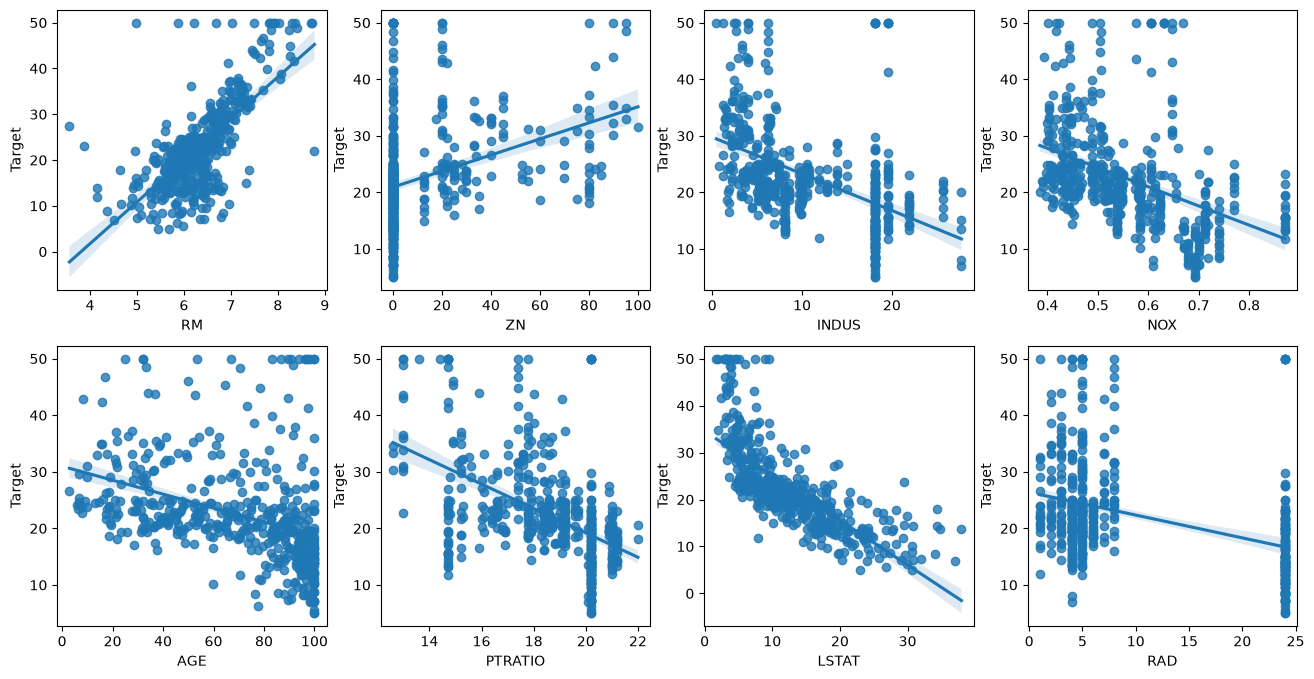

In [7]:
fig, axs = plt.subplots(figsize=(16, 8), ncols=4, nrows=2)
lm_features = ["RM", "ZN", "INDUS", "NOX", "AGE", "PTRATIO", "LSTAT", "RAD"]
for i, feature in enumerate(lm_features):
    row = int(i / 4)
    col = i % 4
    sns.regplot(x=feature, y="Target", data=bostonDF, ax=axs[row][col])

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

y_target = bostonDF["Target"]
X_data = bostonDF.drop(["Target"], axis=1, inplace=False)

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_target, test_size=0.3, random_state=156
)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_preds = lr.predict(X_test)
mse = mean_squared_error(y_test, y_preds)
rmse = np.sqrt(mse)

print("MSE : {0:.3f} , RMSE : {1:.3F}".format(mse, rmse))
print("Variance score(R2) : {0:.3f}".format(r2_score(y_test, y_preds)))

'''
R2 : 모델이 데이터를 얼마나 잘 설명하는가? / 오차를 제곱하여 큰 오차에 큰 패널티를 주는 평가 지표 
MSE : 예측 오차를 제곱해서 평균한 값은 얼마인가?  
RMSE : 예측 오차의 크기를 원래 단위로 환산하면 얼마인가? / 원래 주택가격 단위로 표현되므로 실제 예측 오차 규모를 이해하기 쉬움
     : 실제 주택가격과 예측가격의 평균적인 오차 규모(실제 주택 가격과 예측 가격의 차이가 대략 4.16정도 차이가 남)
'''

MSE : 17.297 , RMSE : 4.159
Variance score(R2) : 0.757


'\nR2 : 모델이 데이터를 얼마나 잘 설명하는가? / 오차를 제곱하여 큰 오차에 큰 패널티를 주는 평가 지표 \nMSE : 예측 오차를 제곱해서 평균한 값은 얼마인가?  \nRMSE : 예측 오차의 크기를 원래 단위로 환산하면 얼마인가? / 원래 주택가격 단위로 표현되므로 실제 예측 오차 규모를 이해하기 쉬움\n'

In [ ]:
print("절편 값:", lr.intercept_) # 회귀식의 시작점(기본값)
print("회귀 계수값:", np.round(lr.coef_, 1)) # X가 Target에 영향을 미치는 크기

# 절편 값이 10이라는 것은 모든 독립변수(X)가 0일 때 모델이 예측하는 종속변수(Y)의 값이 10이라는 의미
# 회귀계수(Coefficient)는 독립변수(X)가 1단위 증가할 때 종속변수(Y)가 얼마나 변하는지를 나타내는 값

절편 값: 40.99559517216485
회귀 계수값: [  0.    0.    3.4  -0.1  -1.7   0.   -0.6 -19.8  -0.9   0.4   0.1  -0.
   3. ]


In [10]:
coeff = pd.Series(data=np.round(lr.coef_, 1), index=X_data.columns)
coeff.sort_values(ascending=False)

RM          3.4
CHAS        3.0
RAD         0.4
ZN          0.1
AGE         0.0
TAX        -0.0
INDUS       0.0
B           0.0
CRIM       -0.1
LSTAT      -0.6
PTRATIO    -0.9
DIS        -1.7
NOX       -19.8
dtype: float64

## 규제 선형회귀 : Regularized Linear Models(Ridge, Lasso)

* 릿지(Ridge) 회귀 : L2 정규화(유클리드 거리)

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

y_target = bostonDF["Target"]
X_data = bostonDF.drop(["Target"], axis=1, inplace=False)

ridge = Ridge(alpha=10)
neg_mse_scores = cross_val_score(
    ridge, X_data, y_target, scoring="neg_mean_squared_error", cv=5
)

rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

print(" 5 folds 의 개별 Negative MSE scores: ", np.round(neg_mse_scores, 3))
print(" 5 folds 의 개별 RMSE scores : ", np.round(rmse_scores, 3))
print(" 5 folds 의 평균 RMSE : {0:.3f} ".format(avg_rmse))

# RMSE가 5에서 4로 감소했다면 모델의 전반적인 예측 오차 수준이 1,000달러만큼 개선

 5 folds 의 개별 Negative MSE scores:  [-11.422 -24.294 -28.144 -74.599 -28.517]
 5 folds 의 개별 RMSE scores :  [3.38  4.929 5.305 8.637 5.34 ]
 5 folds 의 평균 RMSE : 5.518 


In [12]:
alphas = [0, 0.1, 1, 10, 100]

for alpha in alphas:
    ridge = Ridge(alpha=alpha)

    neg_mse_scores = cross_val_score(
        ridge, X_data, y_target, scoring="neg_mean_squared_error", cv=5
    )

    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print("alpha {0} 일 때 5 folds 의 평균 RMSE : {1:.3f} ".format(alpha, avg_rmse))

alpha 0 일 때 5 folds 의 평균 RMSE : 5.829 
alpha 0.1 일 때 5 folds 의 평균 RMSE : 5.788 
alpha 1 일 때 5 folds 의 평균 RMSE : 5.653 
alpha 10 일 때 5 folds 의 평균 RMSE : 5.518 
alpha 100 일 때 5 folds 의 평균 RMSE : 5.330 


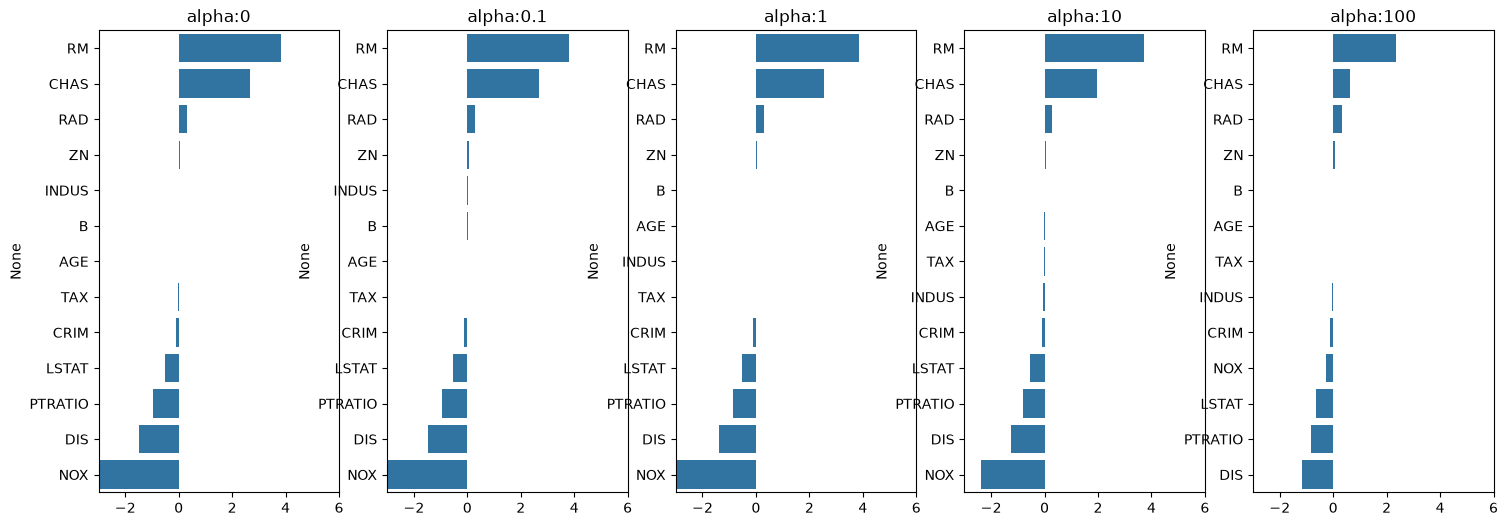

In [13]:
fig, axs = plt.subplots(figsize=(18, 6), nrows=1, ncols=5)
coeff_df = pd.DataFrame()

for pos, alpha in enumerate(alphas):
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_data, y_target)

    coeff = pd.Series(data=ridge.coef_, index=X_data.columns)
    colname = "alpha:" + str(alpha)
    coeff_df[colname] = coeff

    coeff = coeff.sort_values(ascending=False)
    axs[pos].set_title(colname)
    axs[pos].set_xlim(-3, 6)
    sns.barplot(x=coeff.values, y=coeff.index, ax=axs[pos])
plt.show()

In [14]:
sort_column = "alpha:" + str(alphas[0])
coeff_df.sort_values(by=sort_column, ascending=False)

,alpha:0,alpha:0.1,alpha:1,alpha:10,alpha:100
RM,3.809865,3.818233,3.854000,3.702272,2.334536
CHAS,2.686734,2.670019,2.552393,1.952021,0.638335
RAD,0.306049,0.303515,0.290142,0.279596,0.315358
ZN,0.046420,0.046572,0.047443,0.049579,0.054496
INDUS,0.020559,0.015999,-0.008805,-0.042962,-0.052826
B,0.009312,0.009368,0.009673,0.010037,0.009393
AGE,0.000692,-0.000269,-0.005415,-0.010707,0.001212
TAX,-0.012335,-0.012421,-0.012912,-0.013993,-0.015856
CRIM,-0.108011,-0.107474,-0.104595,-0.101435,-0.102202
LSTAT,-0.524758,-0.525966,-0.533343,-0.559366,-0.660764


* 라쏘(Lasso)회귀 : L1 정규화(맨해튼 거리)

In [ ]:
from sklearn.linear_model import Lasso, ElasticNet

def get_linear_reg_eval(
    model_name,
    params=None,
    X_data_n=None,
    y_target_n=None,
    verbose=True,
    return_coeff=True,
):
    coeff_df = pd.DataFrame()
    if verbose:
        print("####### ", model_name, "#######")

    for param in params:
        if model_name == "Ridge":
            model = Ridge(alpha=param)
        elif model_name == "Lasso":
            model = Lasso(alpha=param)
        elif model_name == "ElasticNet":
            model = ElasticNet(alpha=param, l1_ratio=0.7)

        neg_mse_scores = cross_val_score(
            model, X_data_n, y_target_n, scoring="neg_mean_squared_error", cv=5
        )
        avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
        print(
            "alpha {0}일 때 5 폴드 세트의 평균 RMSE: {1:.3f} ".format(param, avg_rmse)
        )

        model.fit(X_data_n, y_target_n)

        if return_coeff:
            coeff = pd.Series(data=model.coef_, index=X_data_n.columns)
            colname = "alpha:" + str(param)
            print(colname)
            coeff_df[colname] = coeff
            
    return coeff_df
    

In [ ]:
lasso_alphas = [0.07, 0.1, 0.5, 1, 3]
coeff_lasso_df = get_linear_reg_eval(
    "Lasso", params=lasso_alphas, X_data_n=X_data, y_target_n=y_target
)

In [ ]:
sort_column = "alpha:" + str(lasso_alphas[0])
coeff_lasso_df.sort_values(by=sort_column, ascending=False)